In [ ]:
import numpy as np
import pandas as pd
import seaborn as sns
import math
import matplotlib.pyplot as plt
%matplotlib inline
from sklearn.metrics import mean_squared_log_error, explained_variance_score
from sklearn.preprocessing import MinMaxScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense

In [ ]:
# Load and preprocess data
# Place synthetic_cibil_scores.csv next to this notebook (on Colab, upload it to /content/).
data = pd.read_csv('synthetic_cibil_scores.csv')
data.head()

,Payment_History,Credit_Utilization,Credit_Age,Number_of_Accounts,Hard_Inquiries,Debt_to_Income_Ratio,CIBIL_Score
0,51,0.314588,18,8,2,0.091025,300.00
1,92,0.512089,22,8,1,0.687709,330.74
2,14,0.940690,24,2,9,0.672397,300.00
3,71,0.047781,17,12,6,0.950627,300.00
4,60,0.352231,6,9,3,0.371552,300.00


In [ ]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 7 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Payment_History       10000 non-null  int64  
 1   Credit_Utilization    10000 non-null  float64
 2   Credit_Age            10000 non-null  int64  
 3   Number_of_Accounts    10000 non-null  int64  
 4   Hard_Inquiries        10000 non-null  int64  
 5   Debt_to_Income_Ratio  10000 non-null  float64
 6   CIBIL_Score           10000 non-null  float64
dtypes: float64(3), int64(4)
memory usage: 547.0 KB


In [ ]:
data.transpose()

,0,1,2,3,4,5,6,7,8,9,...,9990,9991,9992,9993,9994,9995,9996,9997,9998,9999
Payment_History,51.000000,92.000000,14.000000,71.000000,60.000000,20.000000,82.000000,86.000000,74.000000,74.000000,...,7.000000,22.000000,63.000000,92.000000,19.000000,15.000000,16.000000,79.000000,18.000000,7.000000
Credit_Utilization,0.314588,0.512089,0.940690,0.047781,0.352231,0.856572,0.396054,0.199157,0.424794,0.385553,...,0.973941,0.045504,0.950968,0.581937,0.795728,0.430393,0.453838,0.879326,0.895934,0.238689
Credit_Age,18.000000,22.000000,24.000000,17.000000,6.000000,25.000000,15.000000,13.000000,26.000000,26.000000,...,29.000000,9.000000,4.000000,5.000000,7.000000,26.000000,7.000000,11.000000,10.000000,11.000000
Number_of_Accounts,8.000000,8.000000,2.000000,12.000000,9.000000,11.000000,4.000000,1.000000,1.000000,5.000000,...,4.000000,10.000000,11.000000,2.000000,2.000000,12.000000,6.000000,8.000000,7.000000,7.000000
Hard_Inquiries,2.000000,1.000000,9.000000,6.000000,3.000000,0.000000,0.000000,3.000000,4.000000,4.000000,...,9.000000,3.000000,5.000000,1.000000,9.000000,2.000000,1.000000,9.000000,1.000000,6.000000
Debt_to_Income_Ratio,0.091025,0.687709,0.672397,0.950627,0.371552,0.305438,0.172393,0.265289,0.501891,0.837713,...,0.743552,0.699867,0.460524,0.274420,0.285003,0.731168,0.626036,0.584884,0.652609,0.774786
CIBIL_Score,300.000000,330.740000,300.000000,300.000000,300.000000,300.000000,300.020000,305.420000,300.000000,300.000000,...,300.000000,300.000000,300.000000,313.160000,300.000000,300.000000,300.000000,300.000000,300.000000,300.000000


In [ ]:
#checking if there are any null values
data.isnull().sum().sum()

0

In [ ]:
#since 'Credit_Score' is out target column, let's see the unique values there and what percentage each of them contributes
data['CIBIL_Score'].value_counts(normalize=True) * 100

,proportion
CIBIL_Score,
300.00,83.14
300.01,0.25
300.04,0.23
300.02,0.20
300.06,0.14
...,...
336.18,0.01
319.47,0.01
312.20,0.01


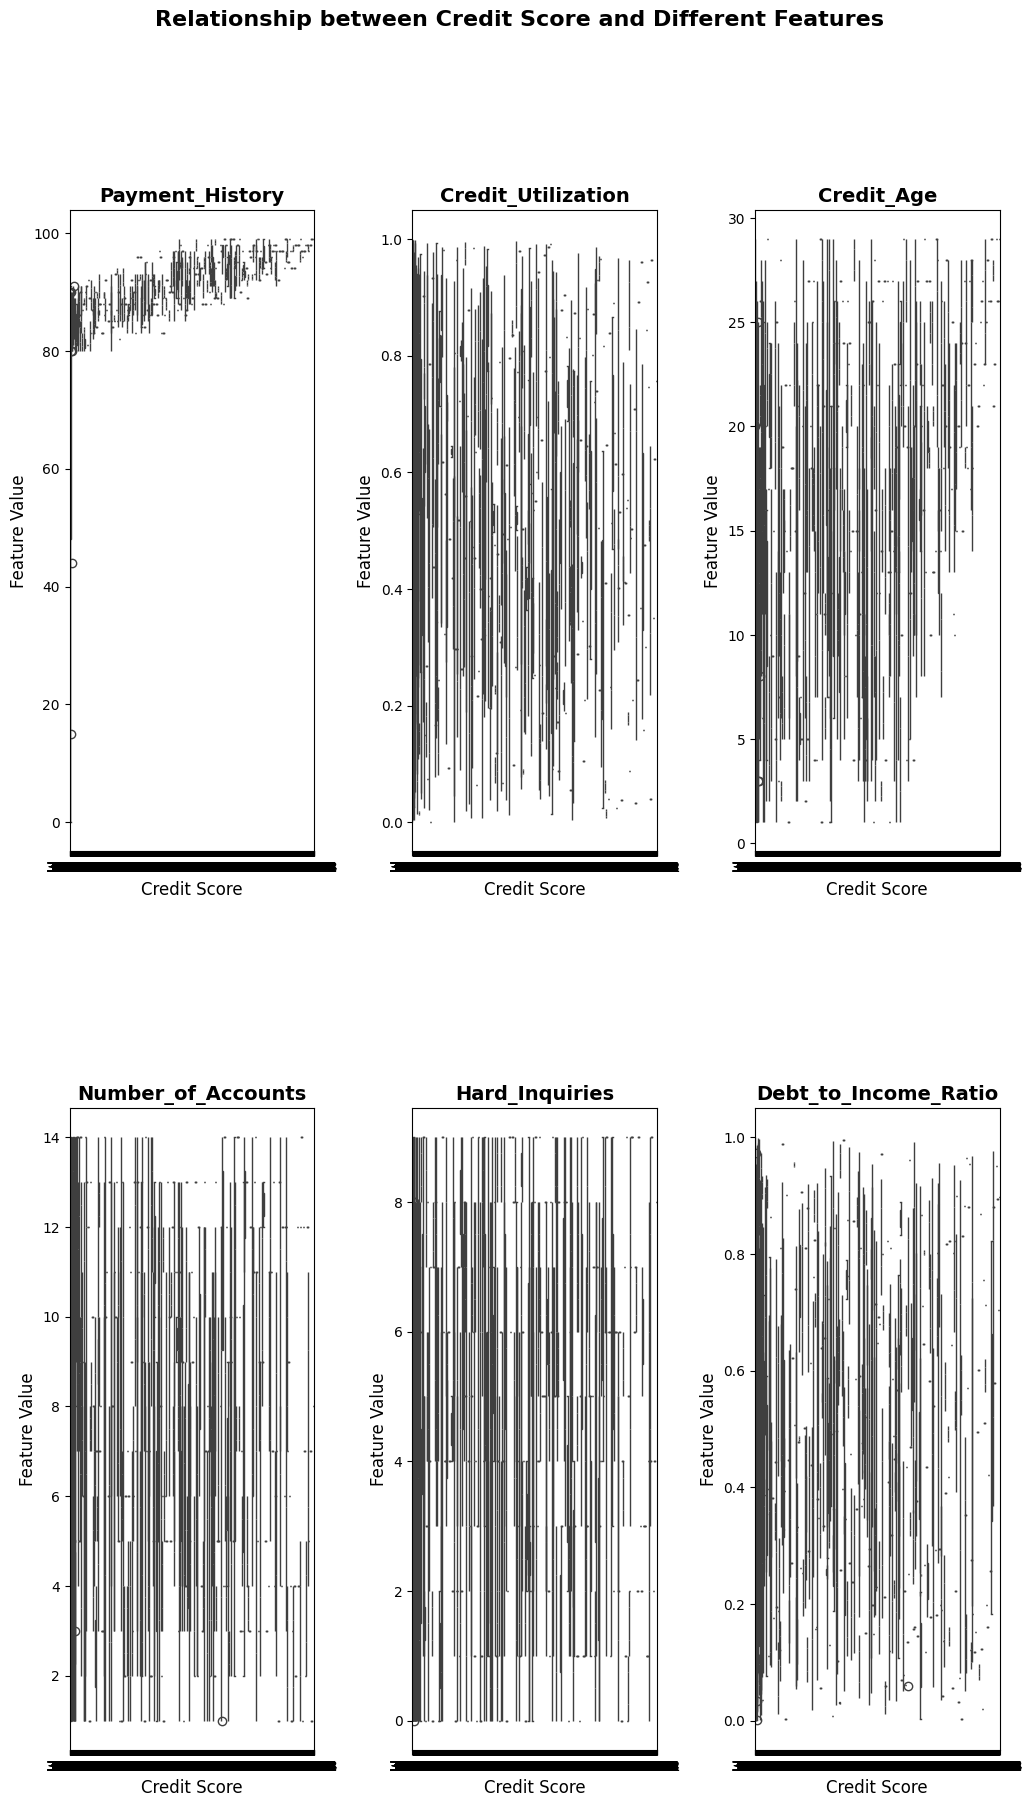

In [ ]:
# Create a figure and a 2x3 grid of subplots
fig, ax = plt.subplots(2, 3, figsize=(12, 20))

# Flatten the 2D array of subplots into a 1D array
ax = ax.flatten()

# Define titles for each subplot
titles = ['Payment_History', 'Credit_Utilization', 'Credit_Age', 'Number_of_Accounts', 'Hard_Inquiries', 'Debt_to_Income_Ratio']

# Plot multiple box plots on the same axis and set titles
sns.boxplot(x='CIBIL_Score', y='Payment_History', data=data, ax=ax[0])
sns.boxplot(x='CIBIL_Score', y='Credit_Utilization', data=data, ax=ax[1])
sns.boxplot(x='CIBIL_Score', y='Credit_Age', data=data, ax=ax[2])
sns.boxplot(x='CIBIL_Score', y='Number_of_Accounts', data=data, ax=ax[3])
sns.boxplot(x='CIBIL_Score', y='Hard_Inquiries', data=data, ax=ax[4])
sns.boxplot(x='CIBIL_Score', y='Debt_to_Income_Ratio', data=data, ax=ax[5])

# Customize each subplot
for i in range(6):
    ax[i].set_title(titles[i], fontsize=14, fontweight='bold')
    ax[i].set_xlabel('Credit Score', fontsize=12)
    ax[i].set_ylabel('Feature Value', fontsize=12)
    ax[i].grid(color='white', linestyle='-', linewidth=0.5, alpha=0.5)

# Add a main title and adjust subplot spacing
fig.suptitle('Relationship between Credit Score and Different Features', fontsize=16, fontweight='bold')
fig.subplots_adjust(hspace=0.4, wspace=0.4)

# Show the plot
plt.show()


In [ ]:
scaler = MinMaxScaler(feature_range=(0, 1))
scaled_data = scaler.fit_transform(data)

In [ ]:
# Optional: mount Google Drive when running on Colab
try:
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    print('Not running on Colab; skipping Drive mount.')

Mounted at /content/drive


In [ ]:
# Prepare time-series data
def create_dataset(data, time_step=7):
    X, y = [], []
    for i in range(len(data) - time_step - 1):  # Adjust loop to avoid overlap
        X.append(data[i:(i + time_step), :])  # Select all features for each timestep
        y.append(data[i + time_step, :])   # Select all features for the target
    return np.array(X), np.array(y)

X, y = create_dataset(scaled_data)

# Hold out the last 20% of sequences (chronological split, no shuffling) for testing
split = int(len(X) * 0.8)
X_train_seq, X_test_seq = X[:split], X[split:]
y_train_seq, y_test_seq = y[:split], y[split:]
print('Train sequences:', X_train_seq.shape, '| Test sequences:', X_test_seq.shape)

In [ ]:
# Build LSTM model
model = Sequential()
model.add(LSTM(50, return_sequences=True, input_shape=(X.shape[1], X.shape[2])))
model.add(LSTM(50, return_sequences=False))
model.add(Dense(25))
model.add(Dense(y.shape[1]))  # Output layer should match the number of target features

/usr/local/lib/python3.10/dist-packages/keras/src/layers/rnn/rnn.py:204: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [ ]:
from tensorflow.keras.losses import MeanSquaredError
from tensorflow.keras.metrics import MeanAbsoluteError
from tensorflow.keras import backend as K
# Define custom metrics
def rmse(y_true, y_pred):
    return K.sqrt(K.mean(K.square(y_pred - y_true)))

def r_squared(y_true, y_pred):
    ss_res = K.sum(K.square(y_true - y_pred))
    ss_tot = K.sum(K.square(y_true - K.mean(y_true)))
    return 1 - ss_res / (ss_tot + K.epsilon())

# Training runs on Min-Max scaled values (0-1), so a "within 10 points" accuracy is only
# meaningful after inverse-scaling; it is computed on the held-out test set further below.
model.compile(optimizer='adam',
              loss=MeanSquaredError(),
              metrics=[MeanAbsoluteError(), rmse, r_squared])

# Train on the training sequences only (validation_split takes the last 20% of them)
history = model.fit(X_train_seq, y_train_seq, epochs=50, batch_size=32, validation_split=0.2)

In [ ]:
# Predict the next step for the last 100 test sequences
predicted_cibil_scores = model.predict(X_test_seq[-100:])
predicted_cibil_scores = scaler.inverse_transform(predicted_cibil_scores)
print(predicted_cibil_scores)

In [ ]:
model.save('cibil_score.h5')

In [ ]:
from tensorflow.keras.models import load_model

In [ ]:
from tensorflow.keras.models import load_model

# Reload the saved model for inference only (compile=False avoids metric
# deserialisation issues between Keras versions; predictions are unaffected)
loaded_model = load_model('cibil_score.h5', compile=False)

In [ ]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, mean_absolute_percentage_error, r2_score

def print_metrics(name, y_true, y_pred, threshold=10):
    """Print regression metrics for one model's CIBIL score predictions."""
    y_true = np.asarray(y_true, dtype=float).ravel()
    y_pred = np.asarray(y_pred, dtype=float).ravel()
    mse = mean_squared_error(y_true, y_pred)
    print(f"--- {name} ---")
    print(f"Mean Absolute Error (MAE): {mean_absolute_error(y_true, y_pred):.4f}")
    print(f"Mean Squared Error (MSE): {mse:.4f}")
    print(f"Root Mean Squared Error (RMSE): {math.sqrt(mse):.4f}")
    print(f"Mean Absolute Percentage Error (MAPE): {mean_absolute_percentage_error(y_true, y_pred):.6f}")
    print(f"R-squared (R²): {r2_score(y_true, y_pred):.4f}")
    print(f"Mean Squared Logarithmic Error (MSLE): {mean_squared_log_error(y_true, np.clip(y_pred, 0, None)):.6f}")
    print(f"Explained Variance Score: {explained_variance_score(y_true, y_pred):.4f}")
    print(f"Custom Accuracy (within {threshold} points): {np.mean(np.abs(y_true - y_pred) <= threshold) * 100:.2f}%")

In [ ]:
# Evaluate the LSTM on the held-out test sequences, in original units
predicted_scores = loaded_model.predict(X_test_seq)
predicted_scores = scaler.inverse_transform(predicted_scores)
y_test_original = scaler.inverse_transform(y_test_seq)

# The model predicts all 7 columns; score the CIBIL_Score column (last column)
cibil_idx = list(data.columns).index('CIBIL_Score')
print_metrics('LSTM (held-out test set)', y_test_original[:, cibil_idx], predicted_scores[:, cibil_idx])

In [ ]:
loaded_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                          │ (None, 7, 50)               │          11,600 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ lstm_1 (LSTM)                        │ (None, 50)                  │          20,200 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 25)                  │           1,275 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 7)                   │             182 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 33,259 (129.92 KB)

 Trainable params: 33,257 (129.91 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 2 (12.00 B)

In [ ]:
X = data[['Payment_History',	'Credit_Utilization',	'Credit_Age',	'Number_of_Accounts',
'Hard_Inquiries',	'Debt_to_Income_Ratio']].values
y = data['CIBIL_Score'].values

In [ ]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.33, random_state=42)

In [ ]:
from sklearn.ensemble import RandomForestRegressor # Import Regressor instead of Classifier
model = RandomForestRegressor(n_estimators=300) # Initialize Regressor
model.fit(X_train, y_train) # Fit the model

RandomForestRegressor(n_estimators=300)

In [ ]:
y_pred_rf = model.predict(X_test)
y_pred_rf = np.clip(y_pred_rf, 0, None)
print_metrics('Random Forest (33% test set)', y_test, y_pred_rf)

Gradient Boosting

In [ ]:
%pip install xgboost lightgbm scikit-learn

In [ ]:
import xgboost as xgb
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, mean_squared_log_error, explained_variance_score, mean_absolute_percentage_error


In [ ]:
model_xgb = xgb.XGBRegressor(n_estimators=100, learning_rate=0.1, max_depth=5, random_state=42)

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

In [ ]:
model_xgb.fit(X_train, y_train)

XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=None, device=None, early_stopping_rounds=None,
             enable_categorical=False, eval_metric=None, feature_types=None,
             gamma=None, grow_policy=None, importance_type=None,
             interaction_constraints=None, learning_rate=0.1, max_bin=None,
             max_cat_threshold=None, max_cat_to_onehot=None,
             max_delta_step=None, max_depth=5, max_leaves=None,
             min_child_weight=None, missing=nan, monotone_constraints=None,
             multi_strategy=None, n_estimators=100, n_jobs=None,
             num_parallel_tree=None, random_state=42, ...)

In [ ]:
y_pred_xgb = model_xgb.predict(X_test)
print_metrics('XGBoost (30% test set)', y_test, y_pred_xgb)

In [ ]:
import lightgbm as lgb

model_lgb = lgb.LGBMRegressor(n_estimators=100, learning_rate=0.1, max_depth=5, random_state=42, force_col_wise=True)

In [ ]:
model_lgb.fit(X_train, y_train)

[LightGBM] [Info] Total Bins 665
[LightGBM] [Info] Number of data points in the train set: 7000, number of used features: 6
[LightGBM] [Info] Start training from score 303.246937
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -

LGBMRegressor(force_col_wise=True, max_depth=5, random_state=42)

In [ ]:
# Fit the model first
model_lgb.fit(X_train, y_train)

# Then, make predictions
y_pred_lgb = model_lgb.predict(X_test)

# The rest of your code remains the same
y_test_target = y_test

[LightGBM] [Info] Total Bins 665
[LightGBM] [Info] Number of data points in the train set: 7000, number of used features: 6
[LightGBM] [Info] Start training from score 303.246937
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -

In [ ]:
print_metrics('LightGBM (30% test set)', y_test, y_pred_lgb)

Feedforword Neural Networks

In [ ]:
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.preprocessing import StandardScaler

In [ ]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.3, random_state=42)

# Build the Feedforward Neural Network
model = keras.Sequential([
    layers.Dense(64, activation='relu', input_shape=(X_train.shape[1],)),  # First hidden layer
    layers.Dense(32, activation='relu'),  # Second hidden layer
    layers.Dense(16, activation='relu'),  # Third hidden layer
    layers.Dense(1)  # Output layer (for regression)
])

# Compile the model
model.compile(optimizer='adam', loss='mean_squared_error', metrics=['mae'])

# Train the model
history = model.fit(X_train, y_train, epochs=100, batch_size=32, validation_split=0.2, verbose=1)

# Predict on the test set
y_pred = model.predict(X_test)

# Evaluation metrics (this network's own predictions)
print_metrics('Feed-forward NN (30% test set)', y_test, y_pred.ravel())